# Demo ECA&D OGC EDR API for RODEO project
## Abstract
This notebook demonstrates how to explore the ECA&D non-blended collection through the OGC Environmental Data Retrieval (EDR) API used in the RODEO project. It walks through the main discovery and request patterns: inspecting collection metadata, finding stations, requesting station time series, and running polygon queries for larger regions.

Each API request prints the full URL before the response is processed. This makes the notebook useful even if you are not focused on Python: the printed URL shows what the API call looks like and can be copied into a browser or another client.

The notebook is structured as follows:
1. Set up the Python environment and helper functions for readable API requests.
2. Inspect what the ECA&D collection provides, including variables, metadata, and spatial/temporal coverage.
3. Plot all available ECA&D stations to understand the observation network.
4. Query an individual station, using De Bilt as an example, and inspect returned observations.
5. Run polygon queries, using an illustrative Rhine-area polygon, to retrieve observations for a region.

Last update: 2026.03.01

J.R. Angevaare (joran.angevaare@knmi.nl)

## Not included in this demonstration
 - area query (https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/docs#/ecad-nonblended/get_collections_ecad_nonblended_area)
 - position query (https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/docs#/ecad-nonblended/get_collections_ecad_nonblended_position)
 - netcdf4 requests (see basic_demo.ipynb)


## Resources
 - For ECA&D see [www.ecad.eu](http://www.ecad.eu/)
 - For the technical (swagger) documation of the API, examples and settings, please see https://api.meteogate.eu/eu-eumetnet-climate-observations

## Setup and helper functions

This first block imports the packages used throughout the notebook. 

In [49]:
import numpy as np
import cartopy
import pandas as pd
import requests
import pprint
import matplotlib.pyplot as plt
import datetime
import time
from shapely import wkt
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import ipywidgets as widgets
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import ipywidgets as widgets
from matplotlib.colors import LogNorm

This block defines the API endpoint and the collection used in all following requests. `base_url` points to the EUMETNET Climate Observations EDR API, `collection` selects the ECA&D non-blended data, and `SCREEN_WIDTH` controls how wide printed example responses are shown.

In [50]:
base_url = "https://api.meteogate.eu/eu-eumetnet-climate-observations/v1"
collection = "ecad-nonblended"
SCREEN_WIDTH = 120

This helper wraps `requests.get`. It prints the full URL that is sent to the API before making the request, reports how long the request took, checks for HTTP errors, and returns the JSON response as a Python dictionary. The printed URL is useful for non-Python users because it shows the endpoint and query parameters directly.

In [51]:
def get_request(url, params=None, **kwargs):
    """Get request, print url of the formatted request"""
    print(
        requests.Request("GET", url, params=params, **kwargs).prepare().url,
    )
    t0 = time.time()
    r = requests.get(url, params=params, **kwargs)
    print(f"API call took {time.time()-t0:.2g} s")
    r.raise_for_status()
    return r.json()

## Collection metadata

Before requesting observations, we first ask the API for metadata about the ECA&D non-blended collection. This tells us what the collection is, where it comes from, and what usage information is attached to it. The first output line of the request cell is the exact API URL.

In [52]:
collection_info = get_request(f"{base_url}/collections/{collection}")

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended
API call took 0.43 s


The raw metadata response contains a description field. This block prints that description in a readable form, so the notebook shows the collection summary and attribution information directly.

In [53]:
print("".join(collection_info["description"]))

European Climate Assessment & Dataset (ECA&D)

The non-blended series (this collection) are the series as provided by the participants. The provided data focuses on
European meteorological  observations. For more information on ECA&D and additional datasets, see https://www.ecad.eu.
The Algorithm Theoretical Basis Document can be found here https://www.ecad.eu/documents/atbd.pdf.

These data can be used for non-commercial research and education provided that the following source is acknowledged:
Klein Tank, A.M.G. and Coauthors, 2002. Daily dataset of 20th-century surface air temperature and precipitation
series for the European Climate Assessment. Int. J. of Climatol., 22, 1441-1453.
DOI: https://doi.org/10.1002/joc.773

Data and metadata available at https://www.ecad.eu


## Plot all stations in ECA&D

This section retrieves all station locations in the collection and turns the response into a table that is easier to inspect and plot. The goal is to understand where the stations are and how much observational coverage each station contributes. The request cell prints the `/locations` URL before showing the response.

In [54]:
stations = get_request(f"{base_url}/collections/{collection}/locations")
print("-- example response --")
pprint.pprint(stations["features"][0], width=SCREEN_WIDTH)

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/locations
API call took 14 s
-- example response --
{'geometry': {'coordinates': [14.8, 56.86667], 'type': 'Point'},
 'id': 'ecad_0000001',
 'properties': {'country_code': 'SE',
                'height_above_mean_sea_level': 166.0,
                'provider': {'Marcus Flarup': {'cc13': [['1961-01-02T00:00:00', '1995-11-15T00:00:00']],
                                               'dd4': [['1947-01-02T00:00:00', '1995-11-15T00:00:00']],
                                               'pp18': [['1961-01-02T00:00:00', '1995-11-15T00:00:00']],
                                               'rr9': [['1860-01-02T00:00:00', '2019-09-17T00:00:00']],
                                               'sd5': [['1881-10-27T00:00:00', '2019-05-01T00:00:00']],
                                               'tg6': [['1860-01-02T00:00:00', '2006-12-01T00:00:00']],
                                               'tn2':

This small check counts how many station features were returned by the `/locations` endpoint. It is a quick sanity check that the station discovery request returned the full network.

In [55]:
print(f'In total, we have {len(stations["features"])} stations')

In total, we have 22215 stations


The helper function below estimates the total number of observation days available for a station by reading the time ranges in the station metadata. This value is later used to color the station map by data availability.

The station response is CovJson (GeoJson-like) and nested, which is useful for APIs but not ideal for analysis. This block flattens the important fields into a pandas DataFrame: station id, elevation, station name, longitude, latitude, and an estimated number of observation days.

In [56]:
%%time


def get_days_of_observation_time(s: dict):
    n_total_days = 0
    for provided_variables in s["properties"]["provider"].values():
        for date_range in provided_variables.values():
            date_start, date_end = date_range[0]
            dt = datetime.datetime.fromisoformat(
                date_end
            ) - datetime.datetime.fromisoformat(date_start)
            n_total_days += dt.days
    return n_total_days


stations_dataframe = pd.DataFrame(
    dict(
        sta_id=[s["id"] for s in stations["features"]],
        height_above_mean_sea_level=[
            s["properties"]["height_above_mean_sea_level"] for s in stations["features"]
        ],
        station_name=[s["properties"]["station_name"] for s in stations["features"]],
        lon=[s["geometry"]["coordinates"][0] for s in stations["features"]],
        lat=[s["geometry"]["coordinates"][1] for s in stations["features"]],
        n_obs=[get_days_of_observation_time(s) for s in stations["features"]],
    )
)
stations_dataframe.head()

CPU times: user 35.3 ms, sys: 1.7 ms, total: 37 ms
Wall time: 36.2 ms


,sta_id,height_above_mean_sea_level,station_name,lon,lat,n_obs
0,ecad_0000001,166.0,Vaexjoe,14.80000,56.86667,296780
1,ecad_0000002,160.0,Falun,15.61667,60.61667,313280
2,ecad_0000003,325.0,Stensele,17.16639,65.06667,283765
3,ecad_0000004,93.0,Linkoeping,15.53306,58.40000,238096
4,ecad_0000005,93.0,Linkoeping-Malmslaett,15.53306,58.40000,255405


This block plots the stations on a map of Europe. Each dot is a station, and the color shows the estimated observation coverage. A logarithmic color scale is used because some stations have much longer records than others.

CPU times: user 11.3 ms, sys: 802 μs, total: 12.1 ms
Wall time: 11.5 ms


Text(0.5, 1.0, 'Observations per station in ECA&D')

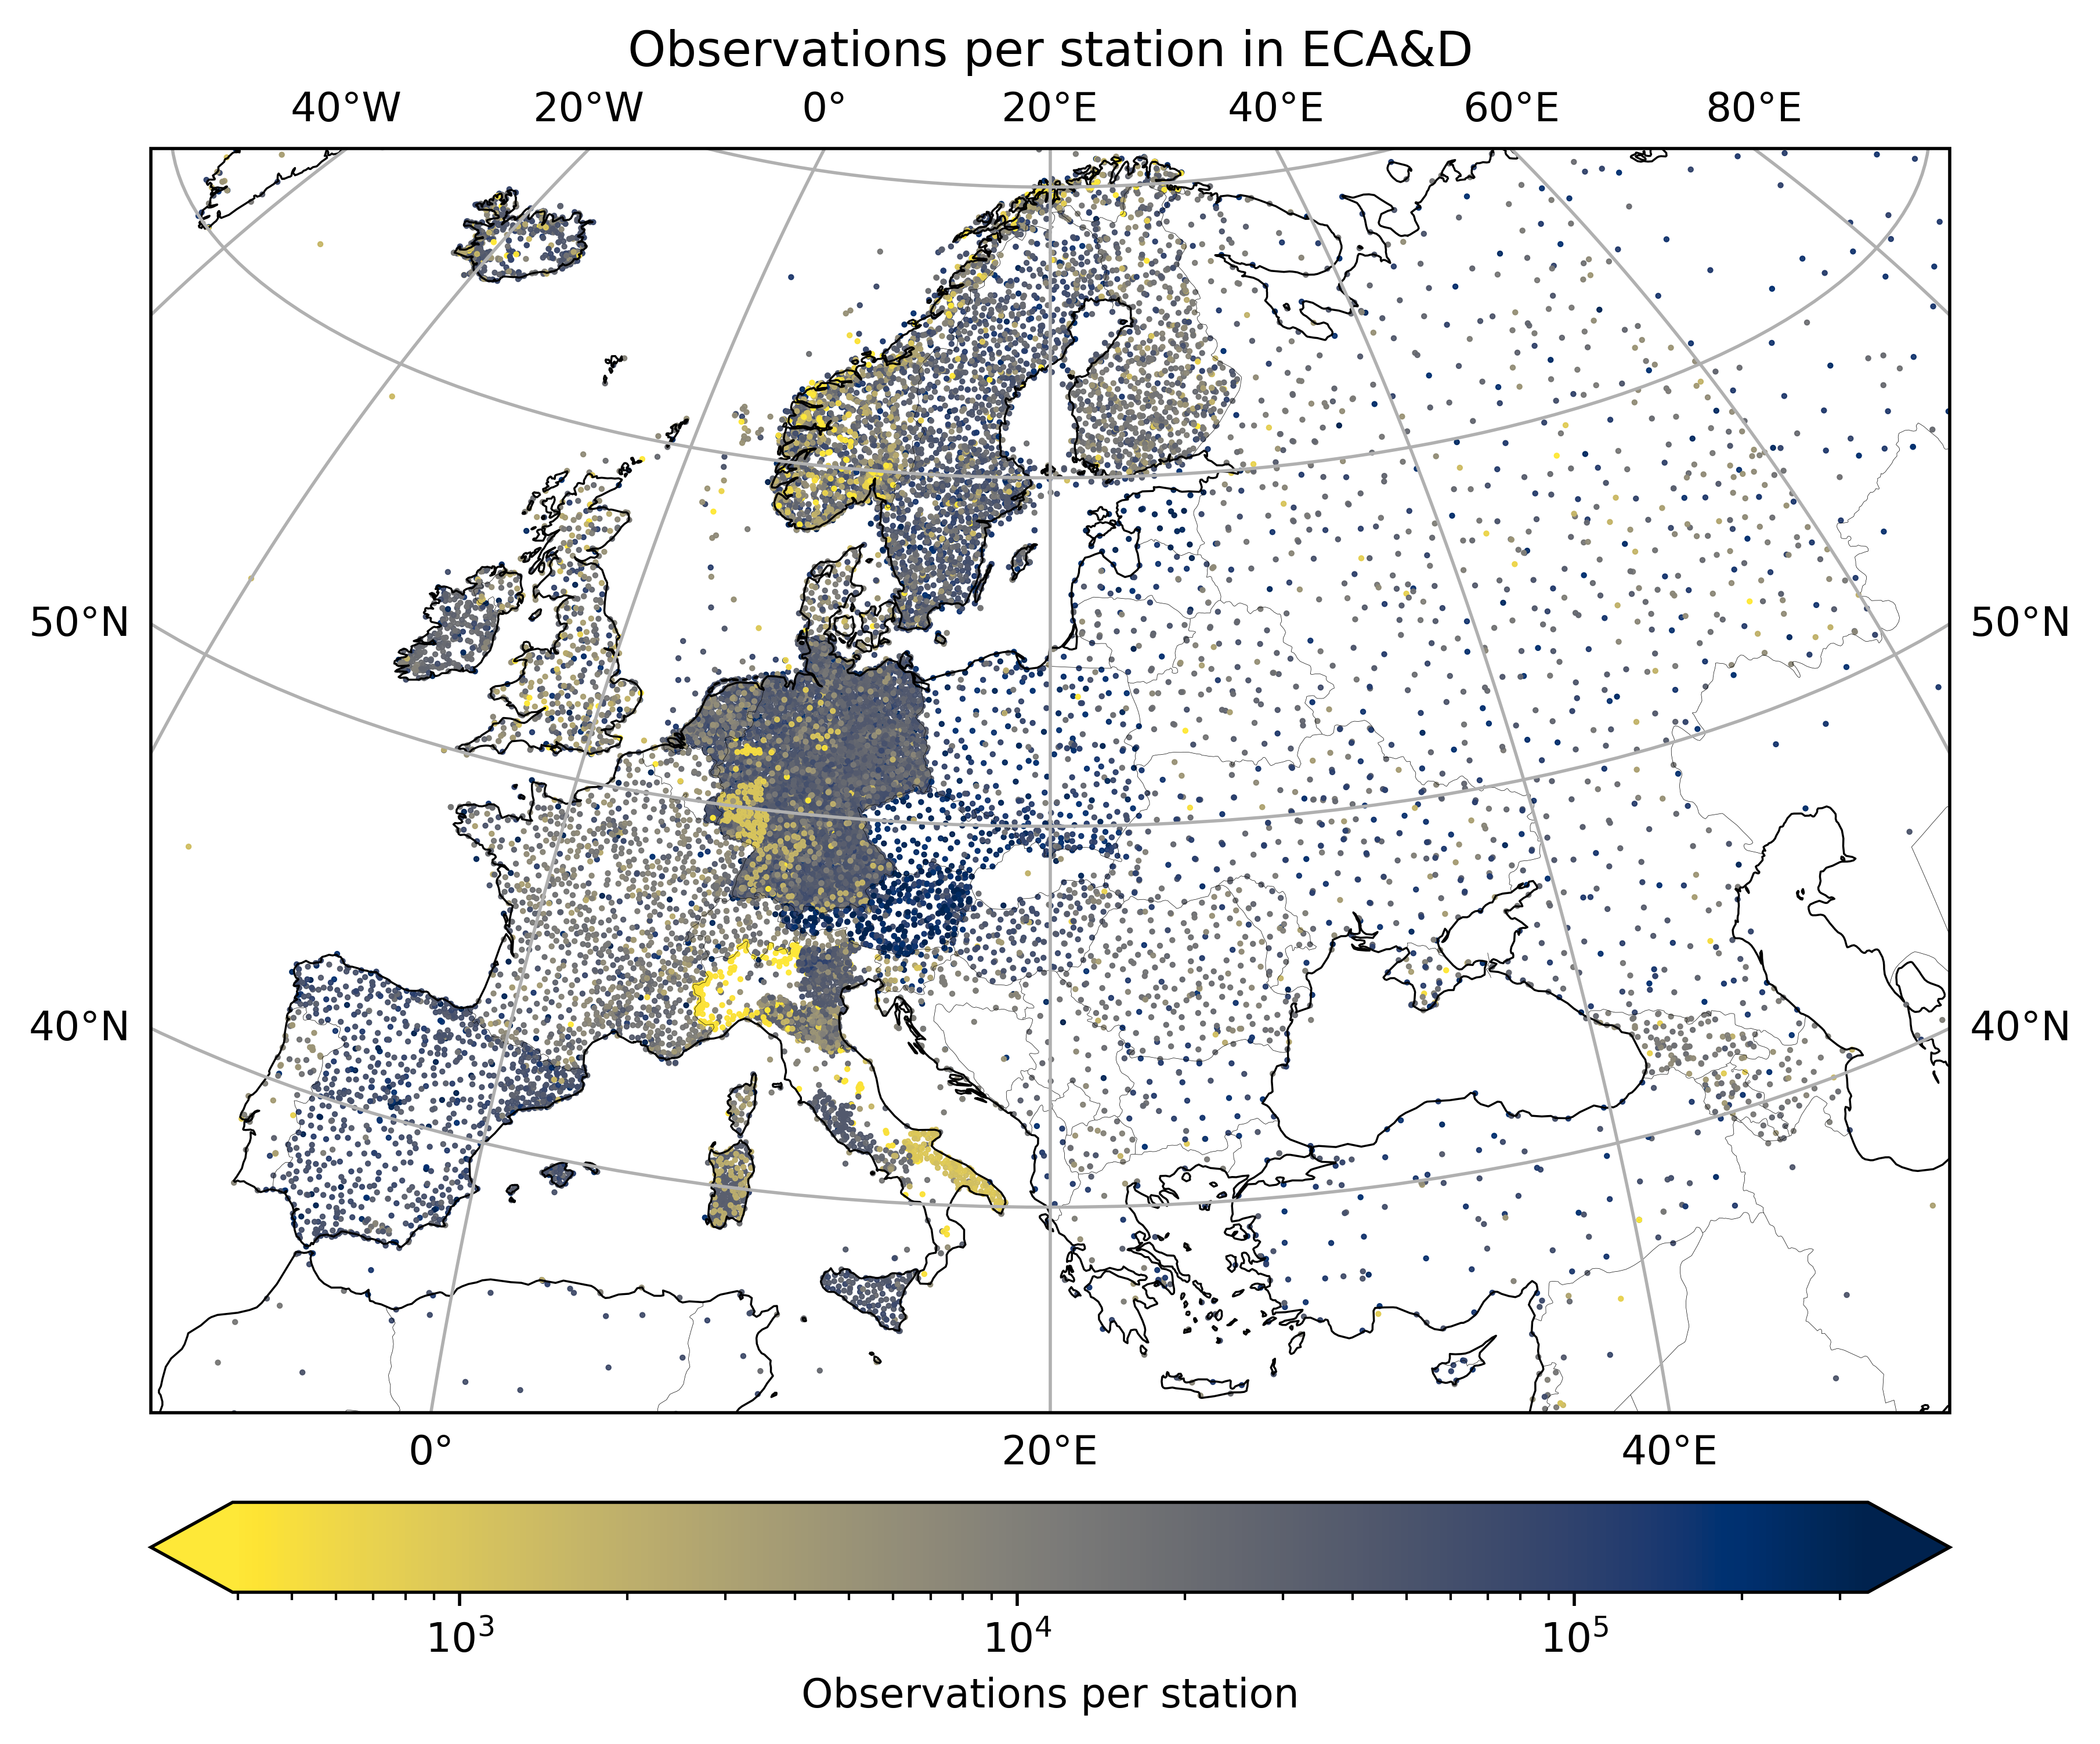

In [57]:
%%time
plt.figure(dpi=500, figsize=(8, 8))
ax = plt.subplot(
    projection=cartopy.crs.NearsidePerspective(20, 40, satellite_height=1e7)
)
ax.coastlines(lw=0.5)

ax.add_feature(cartopy.feature.BORDERS, lw=0.1)
sc = ax.scatter(
    stations_dataframe["lon"],
    stations_dataframe["lat"],
    transform=cartopy.crs.PlateCarree(),
    marker=".",
    c=stations_dataframe["n_obs"],
    norm=LogNorm(
        vmin=np.percentile(stations_dataframe.n_obs, 1),
        vmax=np.percentile(stations_dataframe.n_obs, 99),
    ),
    s=1,
    cmap="cividis_r",
)
cb = plt.colorbar(sc, orientation="horizontal", extend="both", pad=0.05)
cb.ax.set_xlabel("Observations per station")
ax.gridlines(draw_labels=True)
plt.xlim(-60, None)
ax.set_extent([-10, 50, 30, 70])
ax.set_title("Observations per station in ECA&D")

## Station De Bilt

This section demonstrates a point or small-area time-series query using De Bilt in the Netherlands as an example. The query requests mean air temperature for a small bounding box around the station and converts the returned coverage data into a DataFrame. The printed URL shows the bbox, time range, variable, and method used by the request.

In [58]:
params = {
    "method": "mean",
    "standard_name": "air_temperature",
    "bbox": "5.1,52,5.2,52.2",
    "datetime": "2025-11-01T00:00:00Z/2026-04-01T00:00:00Z",
}
data_ecad_de_bilt = get_request(f"{base_url}/collections/{collection}/cube", params)
dataframe_de_bilt_ecad = pd.DataFrame(
    dict(
        end_time=pd.to_datetime(
            data_ecad_de_bilt["coverages"][0]["domain"]["axes"]["t"]["values"]
        ),
        **{
            k: data_ecad_de_bilt["coverages"][0]["ranges"][k]["values"]
            for k in data_ecad_de_bilt["coverages"][0]["ranges"]
        },
    )
)

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/cube?method=mean&standard_name=air_temperature&bbox=5.1%2C52%2C5.2%2C52.2&datetime=2025-11-01T00%3A00%3A00Z%2F2026-04-01T00%3A00%3A00Z
API call took 0.24 s


This block plots the returned De Bilt temperature time series. The y-axis label is taken from the API response metadata, so the plot uses the parameter description and unit provided by the service.

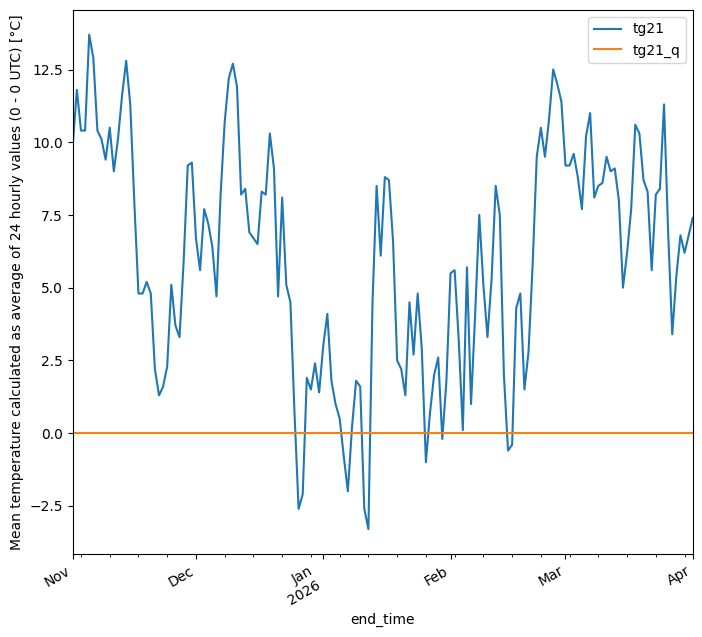

In [59]:
plt.figure(figsize=(8, 8))
dataframe_de_bilt_ecad.plot("end_time", ax=plt.gca())
desc = data_ecad_de_bilt["parameters"]["tg21"]["description"]["en"]
unit = data_ecad_de_bilt["parameters"]["tg21"]["unit"]["symbol"]["value"]
plt.ylabel(f"{desc} [{unit}]")
plt.gcf().autofmt_xdate()

# Polygon queries

The previous section queried a small bounding box around one station. Here we switch to area queries, where the API returns observations for all stations that fall inside a polygon.

## Illustrative Rhine-area polygon

This section uses a hand-drawn polygon around the Rhine corridor as an example area query. It should not be interpreted as a hydrological Rhine basin boundary: the shape is intentionally approximate and only meant to demonstrate how a WKT polygon can be passed to the API. The block below defines the polygon in Well-Known Text (WKT), converts it to a geometry object, and plots it on a simple map so we can visually check the requested area before sending it to the API.


(45.0, 57.0)

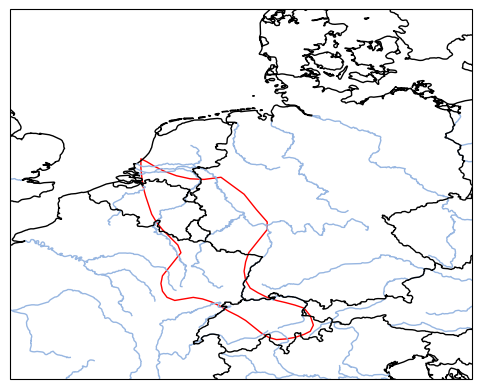

In [60]:
wkt_string = """POLYGON(( 4.25 52.15, 4.45 52.05, 4.70 51.90, 5.00 51.75, 5.40 51.60, 5.85 51.50, 6.30 51.48, 6.85 51.55, 7.6 51.0, 8 50.5, 8.35 50.10, 8.35 49.85, 8.15 49.60, 7.95 49.35, 7.75 49.10, 7.65 48.80, 7.60 48.50, 7.65 48.20, 7.80 47.95, 8.05 47.80, 8.35 47.65, 8.65 47.55, 8.95 47.48, 9.25 47.40, 9.55 47.30, 9.75 47.05, 9.85 46.75, 9.75 46.55, 9.55 46.45, 9.25 46.35, 8.95 46.30, 8.65 46.28, 8.40 46.35, 8.15 46.50, 7.90 46.70, 7.65 46.90, 7.40 47.05, 7.10 47.20, 6.85 47.35, 6.55 47.50, 6.25 47.60, 5.95 47.65, 5.65 47.60, 5.35 47.55, 5.10 47.65, 4.95 47.85, 4.90 48.10, 4.95 48.35, 5.15 48.60, 5.35 48.85, 5.55 49.10, 5.45 49.35, 5.20 49.60, 4.95 49.85, 4.75 50.10, 4.60 50.35, 4.50 50.65, 4.40 50.95, 4.32 51.25, 4.28 51.55, 4.25 51.85, 4.25 52.15 )) """


geom = wkt.loads(wkt_string)

fig = plt.figure()
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_geometries([geom], ccrs.PlateCarree(), facecolor="none", edgecolor="red")
ax.coastlines()
ax.add_feature(cartopy.feature.RIVERS)
ax.add_feature(cartopy.feature.BORDERS)
plt.xlim(0, 15)
plt.ylim(45, 57)

This block sends the illustrative Rhine-area polygon to the `/area` endpoint and requests precipitation observations for a one-week period. The API returns one coverage per matching station inside this approximate example area. The code flattens those coverages into one DataFrame, averages the available precipitation parameters into a single `rr` column, and splits the result into one DataFrame per timestamp for plotting. The printed URL shows how the polygon, time range, and variable are passed to the API.

In [61]:
params = {
    "standard_name": "precipitation_amount",
    "coords": wkt_string,
    "datetime": "2024-05-12T00:00:00Z/2024-05-18T00:00:00Z",
}
data_rhine = get_request(
    f"{base_url}/collections/{collection}/area",
    params,
)

dataframe_rhine = pd.concat(
    [
        pd.DataFrame(
            dict(
                end_time=(n_total_days := c["domain"]["axes"]["t"]["values"]),
                lon=c["domain"]["axes"]["x"]["values"]
                * len(c["domain"]["axes"]["t"]["values"]),
                lat=c["domain"]["axes"]["y"]["values"]
                * len(c["domain"]["axes"]["t"]["values"]),
                sta_id=c["eumetnet:locationId"]
                * len(c["domain"]["axes"]["t"]["values"]),
                **{k: c["ranges"][k]["values"] for k in c["ranges"]},
            )
        )
        for c in data_rhine["coverages"]
    ]
)
rr_params = [p for p in data_rhine["parameters"].keys() if not p.endswith("_q")]
dataframe_rhine["rr"] = np.nanmean(dataframe_rhine[rr_params].values, axis=1)
dataframes = [df for _, df in dataframe_rhine.groupby("end_time")]

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/area?standard_name=precipitation_amount&coords=POLYGON%28%28+4.25+52.15%2C+4.45+52.05%2C+4.70+51.90%2C+5.00+51.75%2C+5.40+51.60%2C+5.85+51.50%2C+6.30+51.48%2C+6.85+51.55%2C+7.6+51.0%2C+8+50.5%2C+8.35+50.10%2C+8.35+49.85%2C+8.15+49.60%2C+7.95+49.35%2C+7.75+49.10%2C+7.65+48.80%2C+7.60+48.50%2C+7.65+48.20%2C+7.80+47.95%2C+8.05+47.80%2C+8.35+47.65%2C+8.65+47.55%2C+8.95+47.48%2C+9.25+47.40%2C+9.55+47.30%2C+9.75+47.05%2C+9.85+46.75%2C+9.75+46.55%2C+9.55+46.45%2C+9.25+46.35%2C+8.95+46.30%2C+8.65+46.28%2C+8.40+46.35%2C+8.15+46.50%2C+7.90+46.70%2C+7.65+46.90%2C+7.40+47.05%2C+7.10+47.20%2C+6.85+47.35%2C+6.55+47.50%2C+6.25+47.60%2C+5.95+47.65%2C+5.65+47.60%2C+5.35+47.55%2C+5.10+47.65%2C+4.95+47.85%2C+4.90+48.10%2C+4.95+48.35%2C+5.15+48.60%2C+5.35+48.85%2C+5.55+49.10%2C+5.45+49.35%2C+5.20+49.60%2C+4.95+49.85%2C+4.75+50.10%2C+4.60+50.35%2C+4.50+50.65%2C+4.40+50.95%2C+4.32+51.25%2C+4.28+51.55%2C+4.25+51.85%2C+4.

/var/folders/3m/z6qcvmc974x8x6v54yhtqt540000gn/T/ipykernel_14908/1004452128.py:29: RuntimeWarning: Mean of empty slice
  dataframe_rhine["rr"] = np.nanmean(dataframe_rhine[rr_params].values, axis=1)


This final plotting block creates an interactive map for the illustrative Rhine-area precipitation query. The slider selects the timestamp to display, and each frame colors the returned stations by precipitation amount while keeping the approximate polygon outline visible for context.

In [ ]:
kw = dict(transform=ccrs.PlateCarree(), marker=".", cmap="Blues", vmin=0, vmax=50)


def plot_frame(i):
    plt.clf()  # clear current figure
    ax = plt.axes(projection=ccrs.PlateCarree())

    df = dataframes[i]
    scat = ax.scatter(df["lon"], df["lat"], c=df["rr"], **kw)

    plt.colorbar(
        scat, orientation="vertical", label="Precipitation [mm]", pad=0.1, extend="max"
    )
    ax.coastlines()
    ax.add_feature(cartopy.feature.BORDERS)
    ax.add_geometries([geom], ccrs.PlateCarree(), facecolor="none", edgecolor="red")
    plt.title(f"{df.iloc[0]['end_time']}")


plt.figure(dpi=100)
widgets.interact(plot_frame, i=(0, len(dataframes) - 1))

<Figure size 640x480 with 0 Axes>

interactive(children=(IntSlider(value=3, description='i', max=6), Output()), _dom_classes=('widget-interact',)…

<function __main__.plot_frame(i)>